# import package

In [3]:
# Google Colab 专用代码，本地 Jupyter 不需要运行
# from google.colab import drive
# drive.mount('/content/drive/')

print("本地 Jupyter 环境：跳过 Google Drive 挂载")

本地 Jupyter 环境：跳过 Google Drive 挂载


In [4]:
import sys

In [5]:
# 在本地仓库中寻找论文 notebook 依赖的旧版源码文件

from pathlib import Path

current_dir = Path.cwd()
repo_root = current_dir.parent

print("当前 notebook 目录：", current_dir)
print("搜索范围：", repo_root)

target_files = [
    "GeoConformalSpatialRegression.py",
    "GeoSIMCPzhao.py"
]

found_files = {}

for filename in target_files:
    matches = list(repo_root.rglob(filename))
    found_files[filename] = matches

    print(f"\n{filename} 搜索结果：")
    if matches:
        for path in matches:
            print(path)
    else:
        print("未找到")

当前 notebook 目录： E:\GeoSIMCP_Reproduce\geoconformal-main
搜索范围： E:\GeoSIMCP_Reproduce

GeoConformalSpatialRegression.py 搜索结果：
E:\GeoSIMCP_Reproduce\geoconformal-main\build\lib\geoconformal\GeoConformalSpatialRegression.py
E:\GeoSIMCP_Reproduce\geoconformal-main\Codes_Manuscript_GeoSIMCP\Codes_GeoSIMCP\GeoConformal\GeoConformalSpatialRegression.py
E:\GeoSIMCP_Reproduce\geoconformal-main\geoconformal\GeoConformalSpatialRegression.py

GeoSIMCPzhao.py 搜索结果：
E:\GeoSIMCP_Reproduce\geoconformal-main\Codes_Manuscript_GeoSIMCP\Codes_GeoSIMCP\GeoConformal\GeoSIMCPzhao.py


In [6]:
# 使用论文仓库中的原始 GeoCP / GeoSIMCP 源码

from pathlib import Path
import sys
import importlib

manuscript_code_dir = Path(
    r"E:\GeoSIMCP_Reproduce\geoconformal-main"
    r"\Codes_Manuscript_GeoSIMCP"
    r"\Codes_GeoSIMCP"
    r"\GeoConformal"
)

if not manuscript_code_dir.exists():
    raise FileNotFoundError(f"源码目录不存在：{manuscript_code_dir}")

code_dir_str = str(manuscript_code_dir)

if code_dir_str not in sys.path:
    sys.path.insert(0, code_dir_str)

# 清除可能存在的旧缓存
sys.modules.pop("GeoConformalSpatialRegression", None)
sys.modules.pop("GeoSIMCPzhao", None)

GeoConformalSpatialRegression = importlib.import_module(
    "GeoConformalSpatialRegression"
)

GeoSIMCPzhao = importlib.import_module(
    "GeoSIMCPzhao"
)

print("论文原始 GeoCP 模块导入成功：")
print(GeoConformalSpatialRegression.__file__)

print("\n论文原始 GeoSIMCP 模块导入成功：")
print(GeoSIMCPzhao.__file__)

论文原始 GeoCP 模块导入成功：
E:\GeoSIMCP_Reproduce\geoconformal-main\Codes_Manuscript_GeoSIMCP\Codes_GeoSIMCP\GeoConformal\GeoConformalSpatialRegression.py

论文原始 GeoSIMCP 模块导入成功：
E:\GeoSIMCP_Reproduce\geoconformal-main\Codes_Manuscript_GeoSIMCP\Codes_GeoSIMCP\GeoConformal\GeoSIMCPzhao.py


In [7]:
import GeoSIMCPzhao

In [8]:
!pip install xgboost geopandas geoplot contextily

  Using cached geoplot-0.5.1-py3-none-any.whl.metadata (1.7 kB)
  Using cached mapclassify-2.8.1-py3-none-any.whl.metadata (2.8 kB)
Using cached geoplot-0.5.1-py3-none-any.whl (28 kB)
Using cached mapclassify-2.8.1-py3-none-any.whl (59 kB)
   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ------------ --------------------------- 0.5/1.7 MB 2.8 MB/s eta 0:00:01
   ------------------------------ --------- 1.3/1.7 MB 2.9 MB/s eta 0:00:01
   ---------------------------------------- 1.7/1.7 MB 2.7 MB/s  0:00:00
   ---------------------------------------- 0.0/11.0 MB ? eta -:--:--
   --- ------------------------------------ 1.0/11.0 MB 12.5 MB/s eta 0:00:01
   ------ --------------------------------- 1.8/11.0 MB 5.3 MB/s eta 0:00:02
   ------------ --------------------------- 3.4/11.0 MB 6.9 MB/s eta 0:00:02
   ------------------- -------------------- 5.2/11.0 MB 6.9 MB/s eta 0:00:01
   ---------------

In [9]:
import xgboost as xgb
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import geoplot as gplt
import geoplot.crs as gcrs
from sklearn.model_selection import train_test_split
import contextily as cx

# Load data

In [12]:
from pathlib import Path
import pandas as pd

data_path = Path(
    r"E:\GeoSIMCP_Reproduce\geoconformal-main"
    r"\example\seattle_sample_3k.csv"
)

print("数据路径：", data_path)
print("文件是否存在：", data_path.exists())

data = pd.read_csv(data_path)

print("数据读取成功，形状：", data.shape)
data.head()

数据路径： E:\GeoSIMCP_Reproduce\geoconformal-main\example\seattle_sample_3k.csv
文件是否存在： True
数据读取成功，形状： (3000, 12)


,Unnamed: 0,bathrooms,sqft_living,sqft_lot,grade,condition,waterfront,view,age,UTM_X,UTM_Y,log_price
0,0,3.00,2660,4600,8,3,0,0,109,552217.557035,5.274945e+06,6.091315
1,1,2.25,2530,8736,7,4,0,0,57,565692.484331,5.272758e+06,5.790988
2,2,2.00,1390,13464,7,4,0,0,28,562451.661509,5.245291e+06,5.315130
3,3,1.00,940,4264,7,5,0,0,66,546816.935618,5.264407e+06,5.619093
4,4,2.25,2070,7225,8,3,0,0,36,564343.195352,5.244978e+06,5.477121


In [13]:
print("数据形状：", data.shape)
print("字段名称：")
print(data.columns.tolist())

print("\n各字段缺失值：")
print(data.isna().sum())

print("\n重复行数量：", data.duplicated().sum())

数据形状： (3000, 12)
字段名称：
['Unnamed: 0', 'bathrooms', 'sqft_living', 'sqft_lot', 'grade', 'condition', 'waterfront', 'view', 'age', 'UTM_X', 'UTM_Y', 'log_price']

各字段缺失值：
Unnamed: 0     0
bathrooms      0
sqft_living    0
sqft_lot       0
grade          0
condition      0
waterfront     0
view           0
age            0
UTM_X          0
UTM_Y          0
log_price      0
dtype: int64

重复行数量： 0


In [14]:
data

,Unnamed: 0,bathrooms,sqft_living,sqft_lot,grade,condition,waterfront,view,age,UTM_X,UTM_Y,log_price
0,0,3.00,2660,4600,8,3,0,0,109,552217.557035,5.274945e+06,6.091315
1,1,2.25,2530,8736,7,4,0,0,57,565692.484331,5.272758e+06,5.790988
2,2,2.00,1390,13464,7,4,0,0,28,562451.661509,5.245291e+06,5.315130
3,3,1.00,940,4264,7,5,0,0,66,546816.935618,5.264407e+06,5.619093
4,4,2.25,2070,7225,8,3,0,0,36,564343.195352,5.244978e+06,5.477121
...,...,...,...,...,...,...,...,...,...,...,...,...
2995,2995,1.50,1290,8366,7,3,0,0,58,551377.991268,5.259321e+06,5.380211
2996,2996,1.50,1490,12186,7,4,0,0,65,550796.231636,5.291393e+06,5.566895
2997,2997,1.50,1510,16800,8,5,0,0,59,549619.278143,5.288838e+06,5.618048
2998,2998,2.00,1640,3021,7,3,0,2,56,548198.517745,5.279378e+06,5.732394


In [15]:
data = gpd.GeoDataFrame(data, crs="EPSG:32610", geometry=gpd.points_from_xy(x=data.UTM_X, y=data.UTM_Y))
data = data.to_crs(4326)

data['lat'] = data['geometry'].get_coordinates()['x']
data['lon'] = data['geometry'].get_coordinates()['y']

data['price'] = np.power(10, data['log_price']) / 10000

In [16]:
data

,Unnamed: 0,bathrooms,sqft_living,sqft_lot,grade,condition,waterfront,view,age,UTM_X,UTM_Y,log_price,geometry,lat,lon,price
0,0,3.00,2660,4600,8,3,0,0,109,552217.557035,5.274945e+06,6.091315,POINT (-122.305 47.6258),-122.305,47.6258,123.4000
1,1,2.25,2530,8736,7,4,0,0,57,565692.484331,5.272758e+06,5.790988,POINT (-122.126 47.6049),-122.126,47.6049,61.8000
2,2,2.00,1390,13464,7,4,0,0,28,562451.661509,5.245291e+06,5.315130,POINT (-122.173 47.3581),-122.173,47.3581,20.6600
3,3,1.00,940,4264,7,5,0,0,66,546816.935618,5.264407e+06,5.619093,POINT (-122.378 47.5314),-122.378,47.5314,41.6000
4,4,2.25,2070,7225,8,3,0,0,36,564343.195352,5.244978e+06,5.477121,POINT (-122.148 47.3551),-122.148,47.3551,30.0000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2995,2995,1.50,1290,8366,7,3,0,0,58,551377.991268,5.259321e+06,5.380211,POINT (-122.318 47.4853),-122.318,47.4853,24.0000
2996,2996,1.50,1490,12186,7,4,0,0,65,550796.231636,5.291393e+06,5.566895,POINT (-122.322 47.7739),-122.322,47.7739,36.8888
2997,2997,1.50,1510,16800,8,5,0,0,59,549619.278143,5.288838e+06,5.618048,POINT (-122.338 47.751),-122.338,47.7510,41.5000
2998,2998,2.00,1640,3021,7,3,0,2,56,548198.517745,5.279378e+06,5.732394,POINT (-122.358 47.666),-122.358,47.6660,54.0000


In [17]:
y = data.price
X_aspatial = data[['bathrooms', 'sqft_living', 'sqft_lot', 'grade', 'condition', 'waterfront', 'view', 'age']]
X_spatial = data[['bathrooms', 'sqft_living', 'sqft_lot', 'grade', 'condition', 'waterfront', 'view', 'age', 'UTM_X', 'UTM_Y']]
loc = data[['lat','lon']]

# train prediction model

In [4]:
# ===============================
# 构造 GeoSIMCP 所需变量
# ===============================

feature_cols = [
    "bathrooms",
    "sqft_living",
    "sqft_lot",
    "grade",
    "condition",
    "waterfront",
    "view",
    "age"
]


# 目标变量
y = data["log_price"]


# 非空间特征
X_aspatial = data[feature_cols]


# 空间+属性特征
X_spatial = data[
    feature_cols + ["UTM_X", "UTM_Y"]
]


# 坐标
loc = data[
    ["UTM_X", "UTM_Y"]
]


print("变量创建完成")
print("X_aspatial:", X_aspatial.shape)
print("X_spatial:", X_spatial.shape)
print("y:", y.shape)
print("loc:", loc.shape)

变量创建完成
X_aspatial: (3000, 8)
X_spatial: (3000, 10)
y: (3000,)
loc: (3000, 2)


In [5]:
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd

# 1. 读取数据
data_path = Path(
    r"E:\GeoSIMCP_Reproduce\geoconformal-main"
    r"\example\seattle_sample_3k.csv"
)

data = pd.read_csv(data_path)

# 2. 将 UTM 坐标转换成经纬度
data = gpd.GeoDataFrame(
    data,
    crs="EPSG:32610",
    geometry=gpd.points_from_xy(
        data["UTM_X"],
        data["UTM_Y"]
    )
)

data = data.to_crs(epsg=4326)

# 保持作者原来的变量命名
data["lat"] = data.geometry.x
data["lon"] = data.geometry.y

# 作者把 log10 房价还原，并以“万元”为单位
data["price"] = np.power(10, data["log_price"]) / 10000

# 3. 定义预测目标和特征
feature_cols = [
    "bathrooms",
    "sqft_living",
    "sqft_lot",
    "grade",
    "condition",
    "waterfront",
    "view",
    "age"
]

y = data["price"]

# 不包含空间坐标的特征
X_aspatial = data[feature_cols].copy()

# 包含空间坐标的特征
X_spatial = data[
    feature_cols + ["UTM_X", "UTM_Y"]
].copy()

# GeoSIMCP 使用的空间位置
loc = data[["lat", "lon"]].copy()

print("数据准备成功")
print("X_aspatial:", X_aspatial.shape)
print("X_spatial:", X_spatial.shape)
print("y:", y.shape)
print("loc:", loc.shape)

数据准备成功
X_aspatial: (3000, 8)
X_spatial: (3000, 10)
y: (3000,)
loc: (3000, 2)


In [6]:
from sklearn.model_selection import train_test_split

# 严格划分：70% train / 10% calibration / 10% validation / 10% test

(
    X_aspatial_train,
    X_aspatial_remain,
    X_spatial_train,
    X_spatial_remain,
    y_train,
    y_remain,
    loc_train,
    loc_remain
) = train_test_split(
    X_aspatial,
    X_spatial,
    y,
    loc,
    test_size=0.30,
    random_state=42
)

(
    X_aspatial_calib,
    X_aspatial_temp,
    X_spatial_calib,
    X_spatial_temp,
    y_calib,
    y_temp,
    loc_calib,
    loc_temp
) = train_test_split(
    X_aspatial_remain,
    X_spatial_remain,
    y_remain,
    loc_remain,
    test_size=2/3,
    random_state=42
)

(
    X_aspatial_val,
    X_aspatial_test,
    X_spatial_val,
    X_spatial_test,
    y_val,
    y_test,
    loc_val,
    loc_test
) = train_test_split(
    X_aspatial_temp,
    X_spatial_temp,
    y_temp,
    loc_temp,
    test_size=0.5,
    random_state=42
)

print("Train:", len(y_train))
print("Calibration:", len(y_calib))
print("Validation:", len(y_val))
print("Test:", len(y_test))

Train: 2100
Calibration: 300
Validation: 300
Test: 300


In [8]:
import xgboost as xgb

print("XGBoost 导入成功，版本：", xgb.__version__)

XGBoost 导入成功，版本： 3.2.0


In [12]:
model_spatial = xgb.XGBRegressor(
    n_estimators=500,
    max_depth=3,
    min_child_weight=1.0,
    colsample_bytree=1.0
)

In [13]:
model_spatial = xgb.XGBRegressor(n_estimators=500, max_depth=3, min_child_weight=1.0, colsample_bytree=1.0)

In [14]:
model_spatial.fit(X_spatial_train, y_train)

,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,1.0
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


In [15]:
print("当前 y 的名称：", y.name)
print("y 前5个值：")
print(y.head())
print("y 的范围：", y.min(), "至", y.max())

当前 y 的名称： price
y 前5个值：
0    123.40
1     61.80
2     20.66
3     41.60
4     30.00
Name: price, dtype: float64
y 的范围： 8.2 至 363.5000000000002


# GeoCP

In [21]:
## GeoCP
from GeoConformalSpatialRegression import GeoConformalSpatialRegression

geocp_spatial = GeoConformalSpatialRegression(predict_f=model_spatial.predict, nonconformity_score_f=None, miscoverage_level=0.1, bandwidth=0.15, coord_calib=loc_val.values, coord_test=loc_test.values, X_calib=X_spatial_val, y_calib=y_val, X_test=X_spatial_test, y_test=y_test)

In [22]:
results = geocp_spatial.analyze()


In [23]:
results.uncertainty

np.float64(18.16879501342758)

In [24]:
results.coverage_probability

np.float64(0.9366666666666666)

## optimize params

In [25]:
import numpy as np
import matplotlib.pyplot as plt

def interval_score(y_true, lower, upper, alpha=0.1, epsilon=1e-6):
    width = np.maximum(upper - lower, epsilon)
    below = (lower - y_true) * (y_true < lower)
    above = (y_true - upper) * (y_true > upper)
    score = width + (2 / alpha) * (below + above)
    score = np.where(np.isnan(score), 0.0, score)
    return score

def bandwidth_grid_sweep_geocp(
    bandwidth_list,
    model_spatial,
    X_val,
    X_test,
    y_val,
    y_test,
    loc_val,
    loc_test,
    alpha=0.1,
    coverage_threshold=0.9
):
    coverage_list = []
    uncertainty_list = []
    interval_score_list = []

    for bw in bandwidth_list:
        model = GeoConformalSpatialRegression(
            predict_f=model_spatial.predict,
            miscoverage_level=alpha,
            bandwidth=bw,
            coord_calib=loc_val.values,
            coord_test=loc_test.values,
            X_calib=X_val,
            y_calib=y_val,
            X_test=X_test,
            y_test=y_test
        )

        result = model.analyze()
        coverage_list.append(result.coverage_probability)

        # 防止 nan
        unc = np.array(result.geo_uncertainty)
        unc = unc[~np.isnan(unc)]
        uncertainty_list.append(np.mean(unc) if len(unc) > 0 else np.nan)

        lower = np.array(result.lower_bound)
        upper = np.array(result.upper_bound)
        y_true = np.array(y_test)

        score = interval_score(y_true, lower, upper, alpha=alpha)
        score = score[~np.isnan(score)]
        interval_score_list.append(np.mean(score) if len(score) > 0 else np.nan)

    # 找出最优 bandwidth
    mask = np.array(coverage_list) >= coverage_threshold
    masked_score = np.where(mask, interval_score_list, np.inf)
    best_idx = np.argmin(masked_score)
    best_bw = bandwidth_list[best_idx]

    # 可视化
    fig, ax1 = plt.subplots(figsize=(10, 6))

    ax1.plot(bandwidth_list, coverage_list, 'b-', label='Coverage')
    ax1.set_ylabel('Coverage', color='b')
    ax1.tick_params(axis='y', labelcolor='b')

    ax2 = ax1.twinx()
    ax2.plot(bandwidth_list, uncertainty_list, 'r-', label='Mean Uncertainty')
    ax2.set_ylabel('Mean Uncertainty', color='r')
    ax2.tick_params(axis='y', labelcolor='r')

    ax3 = ax1.twinx()
    ax3.spines['right'].set_position(('axes', 1.1))
    ax3.plot(bandwidth_list, interval_score_list, 'g--', label='Interval Score', alpha=0.6)
    ax3.set_ylabel('Interval Score', color='g')
    ax3.tick_params(axis='y', labelcolor='g')

    ax1.axvline(x=best_bw, color='gray', linestyle='--', alpha=0.5)
    ax1.text(best_bw, coverage_list[best_idx], f'Best bw={best_bw:.2f}', color='gray')

    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    lines3, labels3 = ax3.get_legend_handles_labels()
    ax1.legend(lines1 + lines2 + lines3, labels1 + labels2 + labels3, loc='upper right')

    ax1.set_xlabel('Bandwidth')
    plt.title('Coverage, Uncertainty, and Interval Score vs. Bandwidth')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    print(f"Best Bandwidth (Coverage ≥ {coverage_threshold}):")
    print(f"  Bandwidth       = {best_bw:.3f}")
    print(f"  Coverage        = {coverage_list[best_idx]:.3f}")
    print(f"  Interval Score  = {interval_score_list[best_idx]:.3f}")
    print(f"  Mean Interval   = {uncertainty_list[best_idx]:.3f}")

    return coverage_list, uncertainty_list, interval_score_list


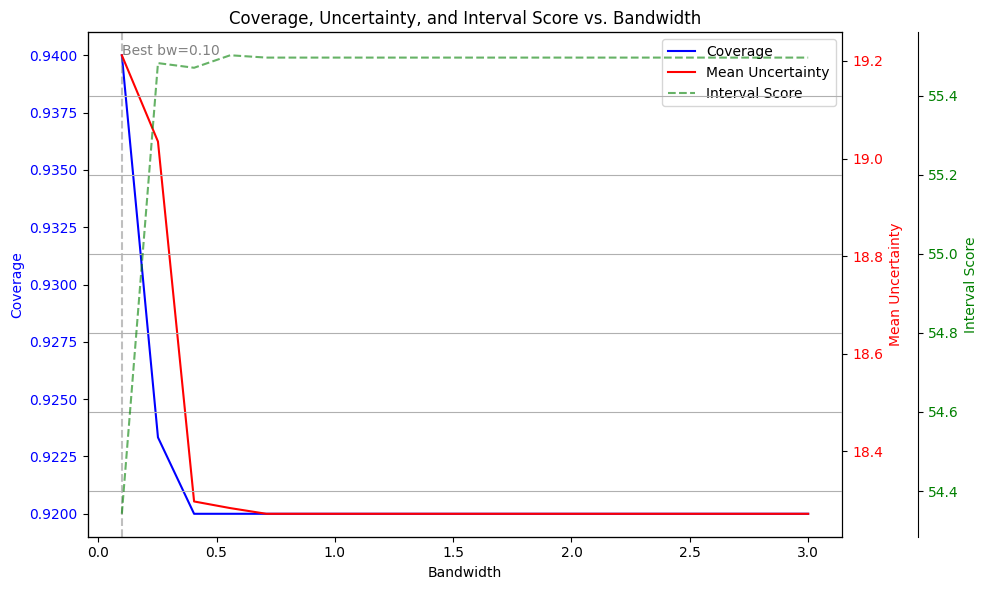

Best Bandwidth (Coverage ≥ 0.9):
  Bandwidth       = 0.100
  Coverage        = 0.940
  Interval Score  = 54.342
  Mean Interval   = 19.212


In [26]:
coverage_list, uncertainty_list, interval_score_list = bandwidth_grid_sweep_geocp(
    bandwidth_list=np.linspace(0.1, 3.0, 20),
    model_spatial=model_spatial,
    X_val=X_spatial_val,
    X_test=X_spatial_test,
    y_val=y_val,
    y_test=y_test,
    loc_val=loc_val,
    loc_test=loc_test,
    alpha=0.1,
    coverage_threshold=0.9
)


# LSCP

In [27]:
!pip install quantile_forest

   ---------------------------------------- 0.0/886.1 kB ? eta -:--:--
   ---------------------------------------- 0.0/886.1 kB ? eta -:--:--
   ---------------------------------------- 0.0/886.1 kB ? eta -:--:--
   ----------- ---------------------------- 262.1/886.1 kB ? eta -:--:--
   ---------------------------------------- 886.1/886.1 kB 1.8 MB/s  0:00:00


In [33]:
import sys

!{sys.executable} -m pip install tqdm

In [34]:
import numpy as np
import matplotlib.pyplot as plt
import LSCP

def interval_score(y_true, lower, upper, alpha=0.1, epsilon=1e-6):
    width = np.maximum(upper - lower, epsilon)
    below = (lower - y_true) * (y_true < lower)
    above = (y_true - upper) * (y_true > upper)
    score = width + (2 / alpha) * (below + above)
    score = np.where(np.isnan(score), 0.0, score)
    return score

def k_grid_sweep_lscp(
    k_list,
    model_spatial,
    X_val,
    X_test,
    y_val,
    y_test,
    loc_val,
    loc_test,
    alpha=0.1,
    coverage_threshold=0.9
):
    coverage_list = []
    uncertainty_list = []
    interval_score_list = []

    for k in k_list:
        model = LSCP.LSCP(
    predict_f=model_spatial.predict,
    miscoverage_level=alpha,
    k=k,
    coord_calib=loc_val.values,
    coord_test=loc_test.values,
    x_calib=X_val,
    y_calib=y_val,
    x_test=X_test,
    y_test=y_test
)

        result = model.analyze()
        coverage_list.append(result.coverage_probability)

        unc = np.array(result.geo_uncertainty)
        unc = unc[~np.isnan(unc)]
        uncertainty_list.append(np.mean(unc) if len(unc) > 0 else np.nan)

        lower = np.array(result.lower_bound)
        upper = np.array(result.upper_bound)
        y_true = np.array(y_test)

        score = interval_score(y_true, lower, upper, alpha=alpha)
        score = score[~np.isnan(score)]
        interval_score_list.append(np.mean(score) if len(score) > 0 else np.nan)

    # 找出最优 k
    mask = np.array(coverage_list) >= coverage_threshold
    masked_score = np.where(mask, interval_score_list, np.inf)
    best_idx = np.argmin(masked_score)
    best_k = k_list[best_idx]

    # 可视化
    fig, ax1 = plt.subplots(figsize=(10, 6))

    ax1.plot(k_list, coverage_list, 'b-', label='Coverage')
    ax1.set_ylabel('Coverage', color='b')
    ax1.tick_params(axis='y', labelcolor='b')

    ax2 = ax1.twinx()
    ax2.plot(k_list, uncertainty_list, 'r-', label='Mean Uncertainty')
    ax2.set_ylabel('Mean Uncertainty', color='r')
    ax2.tick_params(axis='y', labelcolor='r')

    ax3 = ax1.twinx()
    ax3.spines['right'].set_position(('axes', 1.1))
    ax3.plot(k_list, interval_score_list, 'g--', label='Interval Score', alpha=0.6)
    ax3.set_ylabel('Interval Score', color='g')
    ax3.tick_params(axis='y', labelcolor='g')

    ax1.axvline(x=best_k, color='gray', linestyle='--', alpha=0.5)
    ax1.text(best_k, coverage_list[best_idx], f'Best k={best_k}', color='gray')

    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    lines3, labels3 = ax3.get_legend_handles_labels()
    ax1.legend(lines1 + lines2 + lines3, labels1 + labels2 + labels3, loc='upper right')

    ax1.set_xlabel('k (Number of Neighbors)')
    plt.title('Coverage, Uncertainty, and Interval Score vs. k')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    print(f"Best k (Coverage ≥ {coverage_threshold}):")
    print(f"  k               = {best_k}")
    print(f"  Coverage        = {coverage_list[best_idx]:.3f}")
    print(f"  Interval Score  = {interval_score_list[best_idx]:.3f}")
    print(f"  Mean Interval   = {uncertainty_list[best_idx]:.3f}")

    return coverage_list, uncertainty_list, interval_score_list


100%|██████████| 300/300 [00:04<00:00, 61.51it/s]


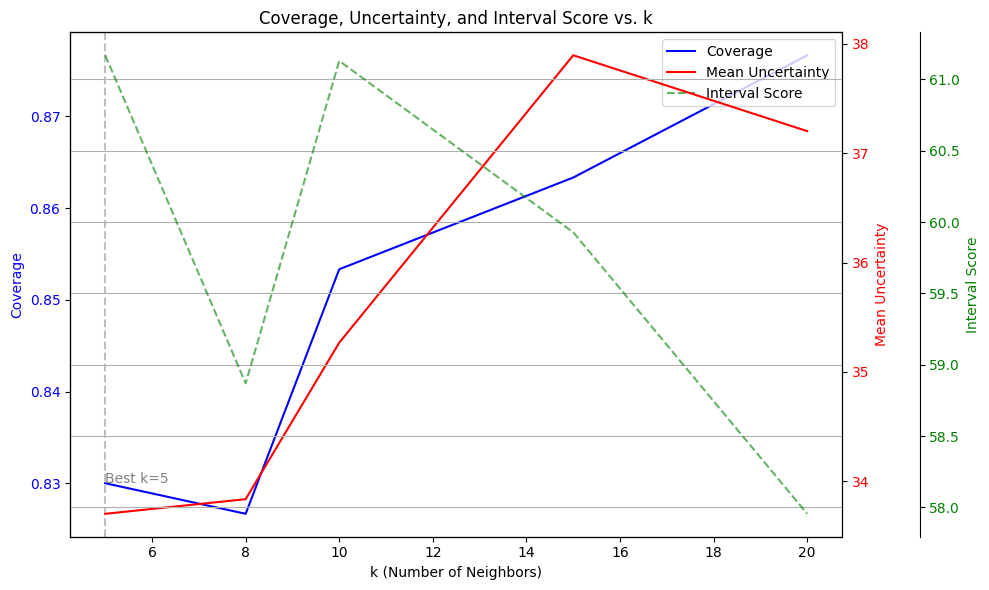

Best k (Coverage ≥ 0.9):
  k               = 5
  Coverage        = 0.830
  Interval Score  = 61.169
  Mean Interval   = 33.702


([np.float64(0.83),
  np.float64(0.8266666666666667),
  np.float64(0.8533333333333334),
  np.float64(0.8633333333333333),
  np.float64(0.8766666666666667)],
 [np.float64(33.702489432405464),
  np.float64(33.83613916419656),
  np.float64(35.26765629174921),
  np.float64(37.89558326518714),
  np.float64(37.201737259608315)],
 [np.float64(61.169482577846445),
  np.float64(58.86984021921749),
  np.float64(61.12989356267593),
  np.float64(59.92849174876774),
  np.float64(57.95578854648491)])

In [35]:
k_grid_sweep_lscp(
    k_list=[5, 8, 10, 15, 20],
    model_spatial=model_spatial,
    X_val=X_spatial_val,
    X_test=X_spatial_test,
    y_val=y_val,
    y_test=y_test,
    loc_val=loc_val,
    loc_test=loc_test,
    alpha=0.1,
    coverage_threshold=0.9
)


# GeoSIMCP

In [36]:
## GeoCP
from GeoSIMCP import GeoSIMConformalSpatialRegression

#X_spatial_val = X_spatial_val.astype(float)
#X_spatial_test = X_spatial_test.astype(float)


geosimcp = GeoSIMConformalSpatialRegression(
    predict_f=model_spatial.predict,            # 原模型，含地理特征
    miscoverage_level=0.1,
    bandwidth=0.15,
    coord_calib=loc_val.values,
    coord_test=loc_test.values,
    X_calib=X_spatial_val,                          # 包含经纬度特征
    y_calib=y_val,
    X_test=X_spatial_test,                          # 包含经纬度特征
    y_test=y_test,
    X_calib_weight=X_aspatial_val,              # 💡 纯特征向量，不含经纬度
    X_test_weight=X_aspatial_test,
    lambda_weight=0
)

results_geosimcp = geosimcp.analyze()
print("Coverage:", results_geosimcp.coverage_probability)
print("Uncertainty:", results_geosimcp.uncertainty)


Coverage: 0.5766666666666667
Uncertainty: 8.214506695821122


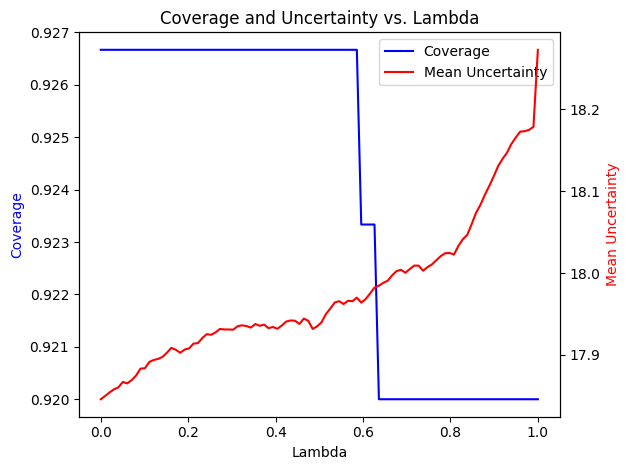

In [37]:
lambda_list = np.linspace(0, 1, 100)
coverage_list = []
uncertainty_list = []

for lam in lambda_list:
    geosimcp = GeoSIMConformalSpatialRegression(
      predict_f=model_spatial.predict,            # 原模型，含地理特征
      miscoverage_level=0.1,
      bandwidth=3,
      coord_calib=loc_val.values,
      coord_test=loc_test.values,
      X_calib=X_spatial_val,                          # 包含经纬度特征
      y_calib=y_val,
      X_test=X_spatial_test,                          # 包含经纬度特征
      y_test=y_test,
      X_calib_weight=X_aspatial_val,              # 💡 纯特征向量，不含经纬度
      X_test_weight=X_aspatial_test,
      lambda_weight=lam
  )
    result = geosimcp.analyze()
    coverage_list.append(result.coverage_probability)
    uncertainty_list.append(result.uncertainty)


fig, ax1 = plt.subplots()

ax2 = ax1.twinx()
ax1.plot(lambda_list, coverage_list, 'b-', label='Coverage')
ax2.plot(lambda_list, uncertainty_list, 'r-', label='Mean Uncertainty')

ax1.set_ylabel('Coverage', color='b')
ax2.set_ylabel('Mean Uncertainty', color='r')
ax1.set_xlabel('Lambda')

# 合并两个 y 轴的图例
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='best')

plt.title('Coverage and Uncertainty vs. Lambda')
plt.tight_layout()
plt.show()



In [38]:
X_spatial_val

,bathrooms,sqft_living,sqft_lot,grade,condition,waterfront,view,age,UTM_X,UTM_Y
1027,2.50,4090,16972,11,3,0,2,8,547243.564784,5.286017e+06
2811,2.25,1860,2670,8,4,0,0,29,561178.929281,5.265896e+06
1089,1.00,1320,5500,7,3,0,0,60,545277.882256,5.268740e+06
173,1.00,1150,6000,7,4,0,1,94,559063.988992,5.281490e+06
1491,2.00,1980,12150,9,3,0,0,21,564028.289837,5.246153e+06
...,...,...,...,...,...,...,...,...,...,...
2663,1.00,1220,5652,6,3,0,0,110,544520.504939,5.269424e+06
1965,2.75,2670,3738,10,3,0,0,2,559990.547931,5.264360e+06
1967,1.50,1820,12686,7,4,0,0,63,560525.062745,5.270890e+06
1210,1.75,1980,3300,7,4,0,0,89,552695.683323,5.280229e+06


### interval score

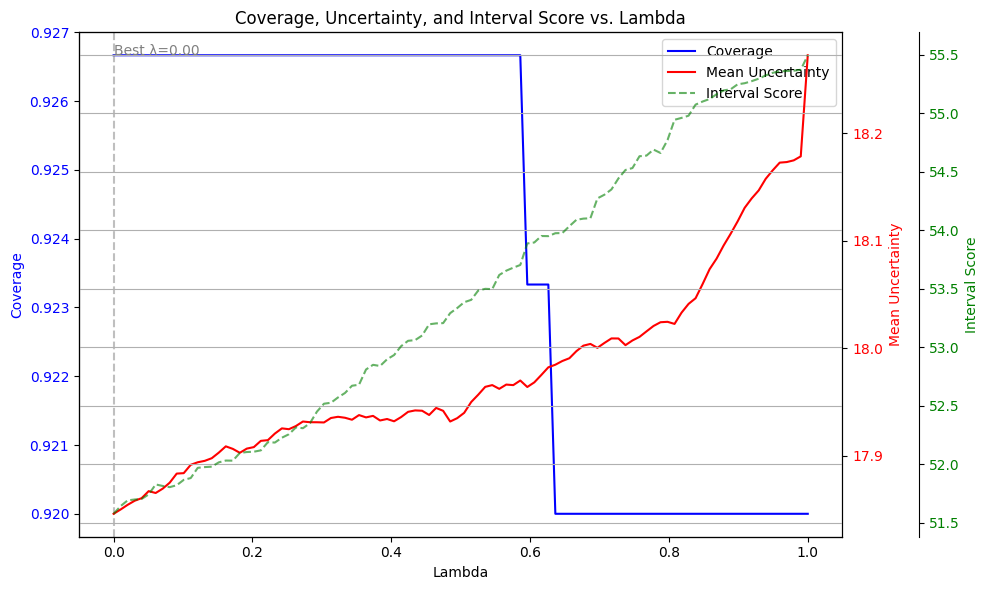

In [39]:
# 1. 自定义函数
def interval_score(y_true, lower, upper, alpha=0.1):
    width = upper - lower
    below = (lower - y_true) * (y_true < lower)
    above = (y_true - upper) * (y_true > upper)
    return width + (2 / alpha) * (below + above)


# 2. 主循环中加入 interval_score 评估
lambda_list = np.linspace(0, 1, 100)
coverage_list = []
uncertainty_list = []
interval_score_list = []

alpha = 0.1

for lam in lambda_list:
    geosimcp = GeoSIMConformalSpatialRegression(
        predict_f=model_spatial.predict,
        miscoverage_level=alpha,
        bandwidth=3,
        coord_calib=loc_val.values,
        coord_test=loc_test.values,
        X_calib=X_spatial_val,
        y_calib=y_val,
        X_test=X_spatial_test,
        y_test=y_test,
        X_calib_weight=X_aspatial_val,
        X_test_weight=X_aspatial_test,
        lambda_weight=lam
    )

    result = geosimcp.analyze()

    coverage_list.append(result.coverage_probability)
    uncertainty_list.append(result.uncertainty)

    lower = np.array(result.lower_bound)
    upper = np.array(result.upper_bound)
    y_true = np.array(y_test)

    score = interval_score(y_true, lower, upper, alpha=alpha)
    interval_score_list.append(np.mean(score))




import matplotlib.pyplot as plt

fig, ax1 = plt.subplots(figsize=(10, 6))

# Coverage - 蓝色
ax1.plot(lambda_list, coverage_list, 'b-', label='Coverage')
ax1.set_ylabel('Coverage', color='b')
ax1.tick_params(axis='y', labelcolor='b')

# Uncertainty - 红色
ax2 = ax1.twinx()
ax2.plot(lambda_list, uncertainty_list, 'r-', label='Mean Uncertainty')
ax2.set_ylabel('Mean Uncertainty', color='r')
ax2.tick_params(axis='y', labelcolor='r')

# Interval Score - 绿色虚线
ax3 = ax1.twinx()
ax3.spines['right'].set_position(("axes", 1.1))
ax3.plot(lambda_list, interval_score_list, 'g--', label='Interval Score', alpha=0.6)
ax3.set_ylabel('Interval Score', color='g')
ax3.tick_params(axis='y', labelcolor='g')

# 标注最优点（最小 interval score）
best_idx = np.argmin(interval_score_list)
best_lambda = lambda_list[best_idx]
ax1.axvline(x=best_lambda, color='gray', linestyle='--', alpha=0.5)
ax1.text(best_lambda, coverage_list[best_idx], f'Best λ={best_lambda:.2f}', color='gray')

# 合并图例
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
lines3, labels3 = ax3.get_legend_handles_labels()
ax1.legend(lines1 + lines2 + lines3, labels1 + labels2 + labels3, loc='upper right')

ax1.set_xlabel('Lambda')
plt.title('Coverage, Uncertainty, and Interval Score vs. Lambda')
plt.grid(True)
plt.tight_layout()
plt.show()


### Optimize Bandwidth

In [40]:
import numpy as np
import matplotlib.pyplot as plt


def interval_score(y_true, lower, upper, alpha=0.1):
    width = upper - lower
    below = (lower - y_true) * (y_true < lower)
    above = (y_true - upper) * (y_true > upper)
    return width + (2 / alpha) * (below + above)


def bandwidth_sweep(
    bandwidth_list,
    model_spatial,
    X_spatial_val,
    X_spatial_test,
    X_aspatial_val,
    X_aspatial_test,
    y_val,
    y_test,
    loc_val,
    loc_test,
    alpha=0.1,
    lambda_weight=0.5
):
    coverage_list = []
    uncertainty_list = []
    interval_score_list = []

    for bw in bandwidth_list:
        model = GeoSIMConformalSpatialRegression(
            predict_f=model_spatial.predict,
            miscoverage_level=alpha,
            bandwidth=bw,
            coord_calib=loc_val.values,
            coord_test=loc_test.values,
            X_calib=X_spatial_val,
            y_calib=y_val,
            X_test=X_spatial_test,
            y_test=y_test,
            X_calib_weight=X_aspatial_val,
            X_test_weight=X_aspatial_test,
            lambda_weight=lambda_weight
        )

        result = model.analyze()

        coverage_list.append(result.coverage_probability)
        uncertainty_list.append(result.uncertainty)

        lower = np.array(result.lower_bound)
        upper = np.array(result.upper_bound)
        y_true = np.array(y_test)

        score = interval_score(y_true, lower, upper, alpha=alpha)
        interval_score_list.append(np.mean(score))

    # 可视化
    fig, ax1 = plt.subplots(figsize=(10, 6))
    ax1.plot(bandwidth_list, coverage_list, 'b-', label='Coverage')
    ax1.set_ylabel('Coverage', color='b')
    ax1.tick_params(axis='y', labelcolor='b')

    ax2 = ax1.twinx()
    ax2.plot(bandwidth_list, uncertainty_list, 'r-', label='Mean Uncertainty')
    ax2.set_ylabel('Mean Uncertainty', color='r')
    ax2.tick_params(axis='y', labelcolor='r')

    ax3 = ax1.twinx()
    ax3.spines['right'].set_position(('axes', 1.1))
    ax3.plot(bandwidth_list, interval_score_list, 'g--', label='Interval Score', alpha=0.6)
    ax3.set_ylabel('Interval Score', color='g')
    ax3.tick_params(axis='y', labelcolor='g')

    best_idx = np.argmin(interval_score_list)
    best_bw = bandwidth_list[best_idx]
    ax1.axvline(x=best_bw, color='gray', linestyle='--', alpha=0.5)
    ax1.text(best_bw, coverage_list[best_idx], f'Best bw={best_bw:.2f}', color='gray')

    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    lines3, labels3 = ax3.get_legend_handles_labels()
    ax1.legend(lines1 + lines2 + lines3, labels1 + labels2 + labels3, loc='upper right')

    ax1.set_xlabel('Bandwidth')
    plt.title('Coverage, Uncertainty, and Interval Score vs. Bandwidth')
    plt.grid(True)
    plt.tight_layout()
    plt.show()


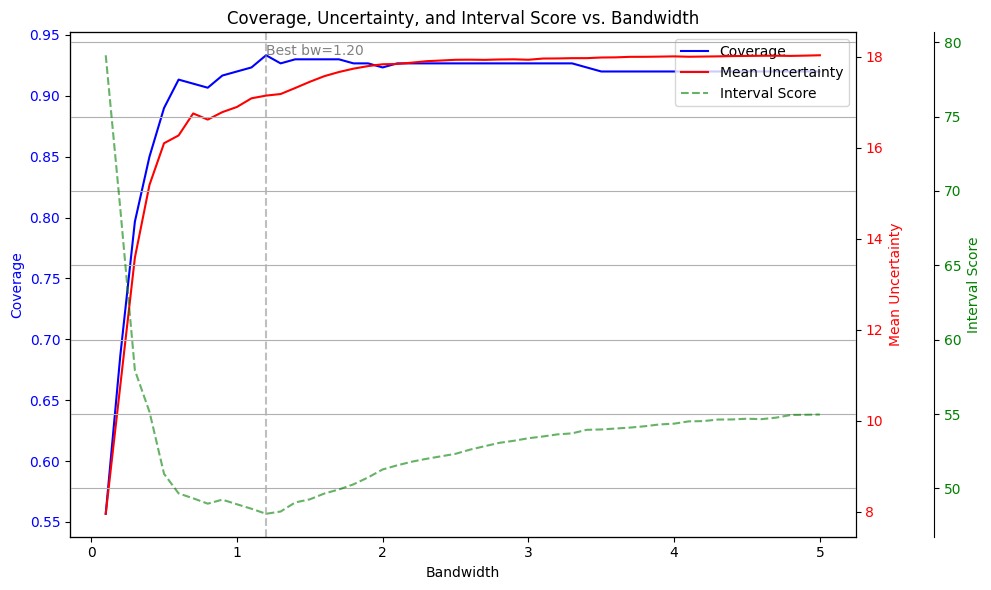

In [41]:
bandwidth_list = np.linspace(0.1, 5.0, 50)

bandwidth_sweep(
    bandwidth_list=bandwidth_list,
    model_spatial=model_spatial,
    X_spatial_val=X_spatial_val,
    X_spatial_test=X_spatial_test,
    X_aspatial_val=X_aspatial_val,
    X_aspatial_test=X_aspatial_test,
    y_val=y_val,
    y_test=y_test,
    loc_val=loc_val,
    loc_test=loc_test,
    alpha=0.1,
    lambda_weight=0.5  # 可以固定一个 lambda
)


## 自动选最优

In [42]:

def interval_score(y_true, lower, upper, alpha=0.1):
    width = upper - lower
    below = (lower - y_true) * (y_true < lower)
    above = (y_true - upper) * (y_true > upper)
    return width + (2 / alpha) * (below + above)

def select_best_lambda_bandwidth(coverage_grid, score_grid, lambda_list, bandwidth_list, threshold=0.9):
    mask = coverage_grid >= threshold
    masked_score = np.where(mask, score_grid, np.inf)
    idx = np.unravel_index(np.argmin(masked_score), masked_score.shape)
    best_lambda = lambda_list[idx[1]]
    best_bandwidth = bandwidth_list[idx[0]]
    return best_lambda, best_bandwidth, masked_score[idx], idx

def bandwidth_lambda_grid_sweep(
    bandwidth_list,
    lambda_list,
    model_spatial,
    X_spatial_val,
    X_spatial_test,
    X_aspatial_val,
    X_aspatial_test,
    y_val,
    y_test,
    loc_val,
    loc_test,
    alpha=0.1,
    coverage_threshold=0.9
):
    coverage_grid = np.zeros((len(bandwidth_list), len(lambda_list)))
    uncertainty_grid = np.zeros((len(bandwidth_list), len(lambda_list)))
    interval_score_grid = np.zeros((len(bandwidth_list), len(lambda_list)))

    for i, bw in enumerate(bandwidth_list):
        for j, lam in enumerate(lambda_list):
            model = GeoSIMConformalSpatialRegression(
                predict_f=model_spatial.predict,
                miscoverage_level=alpha,
                bandwidth=bw,
                coord_calib=loc_val.values,
                coord_test=loc_test.values,
                X_calib=X_spatial_val,
                y_calib=y_val,
                X_test=X_spatial_test,
                y_test=y_test,
                X_calib_weight=X_aspatial_val,
                X_test_weight=X_aspatial_test,
                lambda_weight=lam
            )

            result = model.analyze()

            coverage_grid[i, j] = result.coverage_probability
            uncertainty_grid[i, j] = result.uncertainty

            lower = np.array(result.lower_bound)
            upper = np.array(result.upper_bound)
            y_true = np.array(y_test)

            score = interval_score(y_true, lower, upper, alpha=alpha)
            interval_score_grid[i, j] = np.mean(score)

    best_lambda, best_bw, best_score, idx = select_best_lambda_bandwidth(
        coverage_grid, interval_score_grid, lambda_list, bandwidth_list, threshold=coverage_threshold
    )
    best_coverage = coverage_grid[idx]
    best_uncertainty = uncertainty_grid[idx]

    # 可视化 heatmap with masking
    fig, axs = plt.subplots(1, 3, figsize=(18, 5))

    im1 = axs[0].imshow(coverage_grid, origin='lower', aspect='auto', cmap='Blues',
                        extent=[lambda_list[0], lambda_list[-1], bandwidth_list[0], bandwidth_list[-1]])
    axs[0].set_title('Coverage')
    axs[0].set_xlabel('Lambda')
    axs[0].set_ylabel('Bandwidth')
    fig.colorbar(im1, ax=axs[0])

    im2 = axs[1].imshow(uncertainty_grid, origin='lower', aspect='auto', cmap='Reds',
                        extent=[lambda_list[0], lambda_list[-1], bandwidth_list[0], bandwidth_list[-1]])
    axs[1].set_title('Mean Uncertainty')
    axs[1].set_xlabel('Lambda')
    axs[1].set_ylabel('Bandwidth')
    fig.colorbar(im2, ax=axs[1])

    masked_score_grid = np.where(coverage_grid >= coverage_threshold, interval_score_grid, np.nan)
    im3 = axs[2].imshow(masked_score_grid, origin='lower', aspect='auto', cmap='Greens',
                        extent=[lambda_list[0], lambda_list[-1], bandwidth_list[0], bandwidth_list[-1]])
    axs[2].set_title(f'Interval Score (valid if coverage ≥ {coverage_threshold:.2f})')
    axs[2].set_xlabel('Lambda')
    axs[2].set_ylabel('Bandwidth')
    fig.colorbar(im3, ax=axs[2])

    axs[2].scatter([best_lambda], [best_bw], color='black', label='Best (λ, bw)', marker='x')
    axs[2].legend()

    plt.tight_layout()
    plt.show()

    print(f"Best parameters (coverage ≥ {coverage_threshold}):")
    print(f"  Coverage        = {best_coverage:.3f}")
    print(f"  Lambda          = {best_lambda:.3f}")
    print(f"  Bandwidth       = {best_bw:.3f}")
    print(f"  Interval Score  = {best_score:.3f}")
    print(f"  Mean Interval   = {best_uncertainty:.3f}")

    return coverage_grid, uncertainty_grid, interval_score_grid


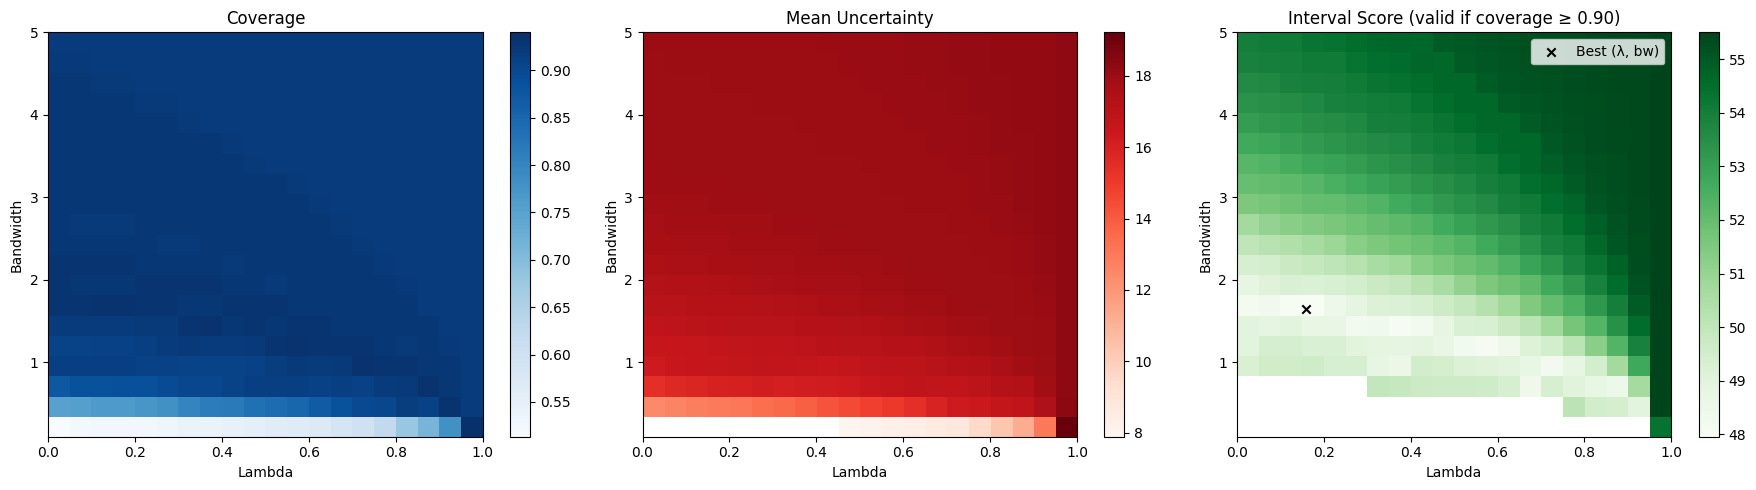

Best parameters (coverage ≥ 0.9):
  Coverage        = 0.933
  Lambda          = 0.158
  Bandwidth       = 1.647
  Interval Score  = 47.958
  Mean Interval   = 17.199


In [43]:
coverage_grid, uncertainty_grid, interval_score_grid = bandwidth_lambda_grid_sweep(
    bandwidth_list=np.linspace(0.1, 5.0, 20),
    lambda_list=np.linspace(0, 1.0, 20),
    model_spatial=model_spatial,
    X_spatial_val=X_spatial_val,
    X_spatial_test=X_spatial_test,
    X_aspatial_val=X_aspatial_val,
    X_aspatial_test=X_aspatial_test,
    y_val=y_val,
    y_test=y_test,
    loc_val=loc_val,
    loc_test=loc_test,
    alpha=0.1,
    coverage_threshold=0.9
)


# GeoSIMCP——zhao2024

In [46]:
import sys

!{sys.executable} -m pip install tqdm

In [48]:
from GeoSIMCPzhao import GeoSIMCPzhao

print("GeoSIMCPzhao 导入成功")
print("类所在模块：", GeoSIMCPzhao.__module__)

GeoSIMCPzhao 导入成功
类所在模块： GeoSIMCPzhao


In [49]:
import numpy as np
import matplotlib.pyplot as plt
from GeoSIMCPzhao import GeoSIMCPzhao

def interval_score(y_true, lower, upper, alpha=0.1, epsilon=1e-6):
    width = np.maximum(upper - lower, epsilon)
    below = (lower - y_true) * (y_true < lower)
    above = (y_true - upper) * (y_true > upper)
    score = width + (2 / alpha) * (below + above)
    score = np.where(np.isnan(score), 0.0, score)
    return score

def select_best_lambda_bandwidth(coverage_grid, score_grid, lambda_list, bandwidth_list, threshold=0.9):
    mask = coverage_grid >= threshold
    masked_score = np.where(mask, score_grid, np.inf)
    idx = np.unravel_index(np.argmin(masked_score), masked_score.shape)
    best_lambda = lambda_list[idx[1]]
    best_bandwidth = bandwidth_list[idx[0]]
    return best_lambda, best_bandwidth, masked_score[idx], idx

def bandwidth_lambda_grid_sweep(
    bandwidth_list,
    lambda_list,
    model_spatial,
    X_spatial_val,
    X_spatial_test,
    X_aspatial_val,
    X_aspatial_test,
    y_val,
    y_test,
    loc_val,
    loc_test,
    alpha=0.1,
    coverage_threshold=0.9
):
    coverage_grid = np.zeros((len(bandwidth_list), len(lambda_list)))
    uncertainty_grid = np.zeros((len(bandwidth_list), len(lambda_list)))
    interval_score_grid = np.zeros((len(bandwidth_list), len(lambda_list)))

    for i, bw in enumerate(bandwidth_list):
        for j, lam in enumerate(lambda_list):
            model = GeoSIMCPzhao(
                predict_f=model_spatial.predict,
                miscoverage_level=alpha,
                bandwidth=bw,
                coord_calib=loc_val.values,
                coord_test=loc_test.values,
                X_calib=X_spatial_val,
                y_calib=y_val,
                X_test=X_spatial_test,
                y_test=y_test,
                X_calib_weight=X_aspatial_val,
                X_test_weight=X_aspatial_test,
                lambda_weight=lam
            )

            result = model.analyze()

            coverage_grid[i, j] = result.coverage_probability
            # Use robust mean for uncertainty
            if result.geo_uncertainty is not None:
                valid_uncertainty = np.array(result.geo_uncertainty)
                valid_uncertainty = valid_uncertainty[~np.isnan(valid_uncertainty)]
                uncertainty_grid[i, j] = np.mean(valid_uncertainty) if len(valid_uncertainty) > 0 else np.nan
            else:
                uncertainty_grid[i, j] = np.nan

            lower = np.array(result.lower_bound)
            upper = np.array(result.upper_bound)
            y_true = np.array(y_test)

            score = interval_score(y_true, lower, upper, alpha=alpha)
            score_filtered = score[~np.isnan(score)]
            interval_score_grid[i, j] = np.mean(score_filtered) if len(score_filtered) > 0 else np.nan

            if np.isnan(interval_score_grid[i, j]):
                print(f"[Warning] NaN interval score at λ={lam:.3f}, bw={bw:.3f}")

    best_lambda, best_bw, best_score, idx = select_best_lambda_bandwidth(
        coverage_grid, interval_score_grid, lambda_list, bandwidth_list, threshold=coverage_threshold
    )
    best_coverage = coverage_grid[idx]
    best_uncertainty = uncertainty_grid[idx]

    fig, axs = plt.subplots(1, 3, figsize=(18, 5))

    im1 = axs[0].imshow(coverage_grid, origin='lower', aspect='auto', cmap='Blues',
                        extent=[lambda_list[0], lambda_list[-1], bandwidth_list[0], bandwidth_list[-1]])
    axs[0].set_title('Coverage')
    axs[0].set_xlabel('Lambda')
    axs[0].set_ylabel('Bandwidth')
    fig.colorbar(im1, ax=axs[0])

    im2 = axs[1].imshow(uncertainty_grid, origin='lower', aspect='auto', cmap='Reds',
                        extent=[lambda_list[0], lambda_list[-1], bandwidth_list[0], bandwidth_list[-1]])
    axs[1].set_title('Mean Uncertainty')
    axs[1].set_xlabel('Lambda')
    axs[1].set_ylabel('Bandwidth')
    fig.colorbar(im2, ax=axs[1])

    masked_score_grid = np.where(coverage_grid >= coverage_threshold, interval_score_grid, np.nan)
    im3 = axs[2].imshow(masked_score_grid, origin='lower', aspect='auto', cmap='Greens',
                        extent=[lambda_list[0], lambda_list[-1], bandwidth_list[0], bandwidth_list[-1]])
    axs[2].set_title(f'Interval Score (valid if coverage ≥ {coverage_threshold:.2f})')
    axs[2].set_xlabel('Lambda')
    axs[2].set_ylabel('Bandwidth')
    fig.colorbar(im3, ax=axs[2])

    axs[2].scatter([best_lambda], [best_bw], color='black', label='Best (λ, bw)', marker='x')
    axs[2].legend()

    plt.tight_layout()
    plt.show()

    print(f"Best parameters (coverage ≥ {coverage_threshold}):")
    print(f"  Coverage        = {best_coverage:.3f}")
    print(f"  Lambda          = {best_lambda:.3f}")
    print(f"  Bandwidth       = {best_bw:.3f}")
    print(f"  Interval Score  = {best_score:.3f}")
    print(f"  Mean Interval   = {best_uncertainty:.3f}")

    return coverage_grid, uncertainty_grid, interval_score_grid


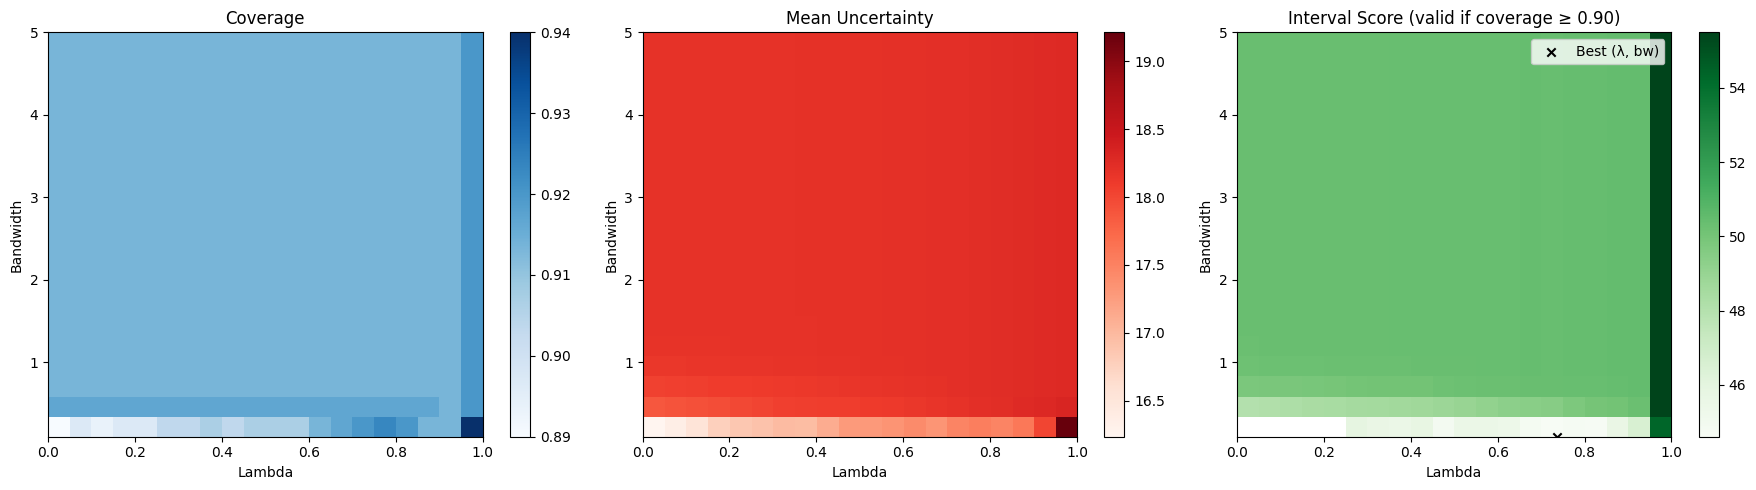

Best parameters (coverage ≥ 0.9):
  Coverage        = 0.920
  Lambda          = 0.737
  Bandwidth       = 0.100
  Interval Score  = 44.606
  Mean Interval   = 17.477


In [50]:
coverage_grid, uncertainty_grid, interval_score_grid = bandwidth_lambda_grid_sweep(
    bandwidth_list=np.linspace(0.1, 5.0, 20),
    lambda_list=np.linspace(0, 1.0, 20),
    model_spatial=model_spatial,
    X_spatial_val=X_spatial_val,
    X_spatial_test=X_spatial_test,
    X_aspatial_val=X_aspatial_val,
    X_aspatial_test=X_aspatial_test,
    y_val=y_val,
    y_test=y_test,
    loc_val=loc_val,
    loc_test=loc_test,
    alpha=0.1,
    coverage_threshold=0.9
)

### GeoSIMCP housing 参数搜索结果

- Coverage threshold: 0.90
- Best coverage: 0.920
- Best lambda: 0.737
- Best bandwidth: 0.100
- Interval score: 44.606
- Mean uncertainty / interval half-width: 17.477
- Approximate mean full interval width: 34.954

备注：最优 bandwidth 位于搜索区间下边界，后续可进行更小 bandwidth 的敏感性分析。